# Can a Simple Neural Network Recognize Images?

**Dataset:** A Large Scale Fish Dataset (Kaggle)

##Setup, Imports & Config

In [ ]:
!pip install seaborn scikit-learn -q

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf
from tensorflow.keras import layers, models, utils

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATASET_DIR = '/content/drive/MyDrive/COMPUTER_VISON/archive/Fish_Dataset/Fish_Dataset'
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

if not os.path.exists(DATASET_DIR):
    print(f"WARNING: DATASET_DIR not found at {DATASET_DIR}. Please check if your Drive is mounted or the path is correct.")
else:
    print(f"DATASET_DIR verified at: {DATASET_DIR}")
    print(f"Image size set to: {IMG_SIZE}")

DATASET_DIR verified at: /content/drive/MyDrive/COMPUTER_VISON/archive/Fish_Dataset/Fish_Dataset
Image size set to: (64, 64)


## Data Loading

In [ ]:
def collect_image_paths(root_dir):

    image_paths = []
    labels = []
    valid_ext = (".png", ".jpg", ".jpeg")

    for dirpath, dirnames, filenames in os.walk(root_dir):
        dirnames[:] = [d for d in dirnames if "GT" not in d]

        for fname in filenames:
            if fname.lower().endswith(valid_ext):
                label = os.path.basename(dirpath)
                image_paths.append(os.path.join(dirpath, fname))
                labels.append(label)

    return image_paths, labels


image_paths, raw_labels = collect_image_paths(DATASET_DIR)

print(f"Found {len(image_paths)} images across {len(set(raw_labels))} classes.")
print("Classes:", sorted(set(raw_labels)))

Found 9000 images across 9 classes.
Classes: ['Black Sea Sprat', 'Gilt-Head Bream', 'Hourse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']


In [ ]:
def collect_image_paths(root_dir):

    image_paths = []
    labels = []
    valid_ext = (".png", ".jpg", ".jpeg")

    for dirpath, dirnames, filenames in os.walk(root_dir):
        dirnames[:] = [d for d in dirnames if "GT" not in d]

        for fname in filenames:
            if fname.lower().endswith(valid_ext):
                label = os.path.basename(dirpath)
                image_paths.append(os.path.join(dirpath, fname))
                labels.append(label)

    return image_paths, labels


image_paths, raw_labels = collect_image_paths(DATASET_DIR)

print(f"Found {len(image_paths)} images across {len(set(raw_labels))} classes.")
print("Classes:", sorted(set(raw_labels)))

Found 9000 images across 9 classes.
Classes: ['Black Sea Sprat', 'Gilt-Head Bream', 'Hourse Mackerel', 'Red Mullet', 'Red Sea Bream', 'Sea Bass', 'Shrimp', 'Striped Red Mullet', 'Trout']


## Preprocessing

In [ ]:
def load_and_preprocess_images(paths, size):
    images = np.zeros((len(paths), size[0], size[1], 3), dtype=np.float32)
    for i, p in enumerate(paths):
        img = tf.keras.utils.load_img(p, target_size=size)
        img_array = tf.keras.utils.img_to_array(img)
        images[i] = img_array
        if i % 500 == 0:
            print(f"  loaded {i}/{len(paths)} images...")
    images /= 255.0
    return images


X = load_and_preprocess_images(image_paths, IMG_SIZE)

label_encoder = LabelEncoder()
y_int = label_encoder.fit_transform(raw_labels)
num_classes = len(label_encoder.classes_)
y = utils.to_categorical(y_int, num_classes=num_classes)

print("X shape:", X.shape)
print("y shape:", y.shape)

  loaded 0/9000 images...
  loaded 500/9000 images...
  loaded 1000/9000 images...
  loaded 1500/9000 images...
  loaded 2000/9000 images...
  loaded 2500/9000 images...
  loaded 3000/9000 images...
  loaded 3500/9000 images...
  loaded 4000/9000 images...
  loaded 4500/9000 images...
  loaded 5000/9000 images...
  loaded 5500/9000 images...
  loaded 6000/9000 images...
  loaded 6500/9000 images...
  loaded 7000/9000 images...
  loaded 7500/9000 images...
  loaded 8000/9000 images...
  loaded 8500/9000 images...
X shape: (9000, 64, 64, 3)
y shape: (9000, 9)


## Train / Validation / Test Split (70 / 15 / 15)

In [ ]:
X_train, X_temp, y_train, y_temp, y_train_int, y_temp_int = train_test_split(
    X, y, y_int,
    test_size=0.30,
    random_state=SEED,
    stratify=y_int,
)

X_val, X_test, y_val, y_test, y_val_int, y_test_int = train_test_split(
    X_temp, y_temp, y_temp_int,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp_int,
)

print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

Train: 6300 | Val: 1350 | Test: 1350


## Model Building

In [ ]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,180,041 (12.13 MB)

 Trainable params: 3,180,041 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

## Compile

In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## Training

In [ ]:
EPOCHS = 20

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
)

Epoch 1/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.2140 - loss: 2.2085 - val_accuracy: 0.4230 - val_loss: 1.6270
Epoch 2/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3119 - loss: 1.7764 - val_accuracy: 0.5207 - val_loss: 1.4558
Epoch 3/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3589 - loss: 1.6531 - val_accuracy: 0.4067 - val_loss: 1.5284
Epoch 4/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3919 - loss: 1.5902 - val_accuracy: 0.5563 - val_loss: 1.3188
Epoch 5/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4405 - loss: 1.4992 - val_accuracy: 0.5696 - val_loss: 1.2221
Epoch 6/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4410 - loss: 1.4876 - val_accuracy: 0.6496 - val_loss: 1.1019
Epoch 7/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4432 - loss: 1.5116 - val_accuracy: 0.5956 - val_loss: 1.2254
Epoch 8/20
197/197 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4522 - loss: 1.4858 - val_accuracy: 0

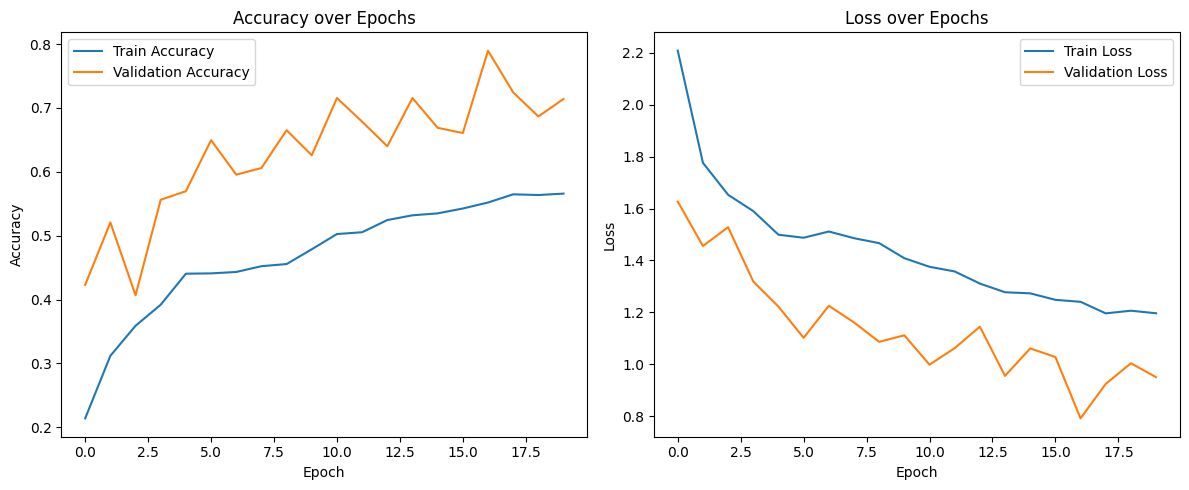

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## Evaluation on Test Set

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Test Loss: 0.9511
Test Accuracy: 0.7185


43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


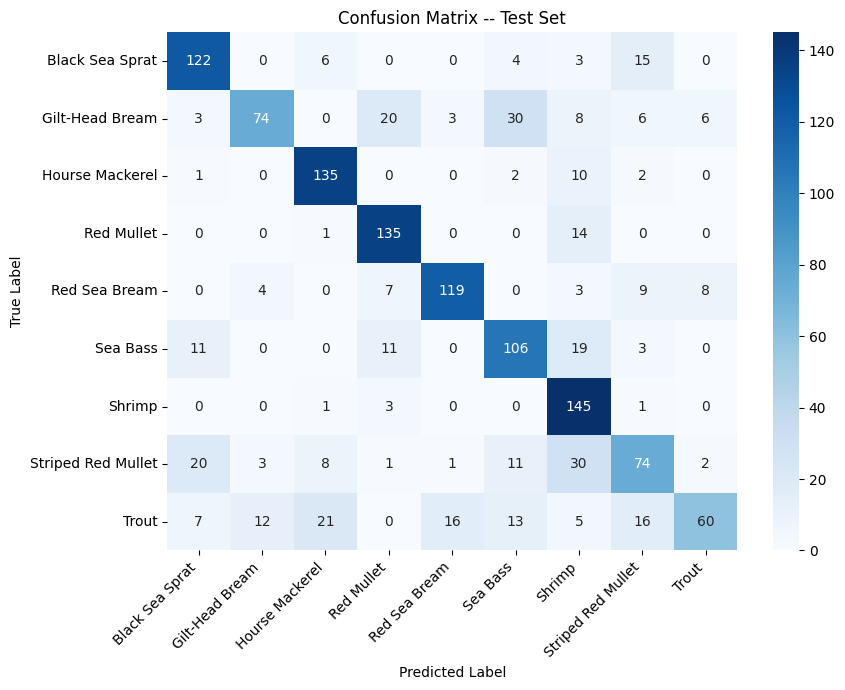

In [ ]:
y_pred_probs = model.predict(X_test)
y_pred_int = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test_int, y_pred_int)
class_names = label_encoder.classes_

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix -- Test Set")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
print("Classification Report:")
print(classification_report(y_test_int, y_pred_int, target_names=class_names))

Classification Report:
                    precision    recall  f1-score   support

   Black Sea Sprat       0.74      0.81      0.78       150
   Gilt-Head Bream       0.80      0.49      0.61       150
   Hourse Mackerel       0.78      0.90      0.84       150
        Red Mullet       0.76      0.90      0.83       150
     Red Sea Bream       0.86      0.79      0.82       150
          Sea Bass       0.64      0.71      0.67       150
            Shrimp       0.61      0.97      0.75       150
Striped Red Mullet       0.59      0.49      0.54       150
             Trout       0.79      0.40      0.53       150

          accuracy                           0.72      1350
         macro avg       0.73      0.72      0.71      1350
      weighted avg       0.73      0.72      0.71      1350

